# owchirp TTS: which constitutive law best explains the master curve?

20 chirp records, $-40$ to $150~^\circ$C in $10~^\circ$C steps, parsed from the
TA Instruments export `owchirp_tts.txt` into `data_owchirp/`. Each record is a
15 s exponential chirp at 500 pts/s exciting $0.43$--$54.5$ rad/s.

Loads your own multi-temperature chirp CSVs, cleans each record with
`rheogp.preprocessing.clean_chirp`, and answers the question this notebook
is built around: **fit every plausible candidate constitutive law jointly
to the SAME set of chirps, and let AIC/BIC say which one wins** -- exactly
the same evidence-based selection used for the two synthetic proofs of
concept (`01_synthetic_fmm_tts.ipynb`, `02_synthetic_fzss_tts.ipynb`), now
applied to a measurement where the "true" model is not known in advance.

This is a generalization of an earlier script that fit only `FMM` by hand;
here `CANDIDATE_MODELS` is a list, `rheogp.mastercurve.compare_master_curve_models`
fits all of them jointly to the same records, and the winner is whichever
minimizes BIC (or AIC, `CRITERION="aic"`).

**You will need to:**
1. Point `DATA_GLOB` at your own CSV files (see `HEADER_MAP` / the temperature
   filename pattern below -- adjust `rheogp.preprocessing.parse_temperature`'s
   `pattern=` argument if your filenames encode T differently).
2. Adjust `CANDIDATE_MODELS`, `T_WINDOW`, `CLEANKW`, `FITKW` to your data.
3. Run the notebook. It writes `results_real.tex` / `table_real.tex` /
   `fig_tts_real.pdf` next to itself for `main.tex`'s real-data section --
   nothing in this repo can produce numbers for that section without your
   files, so those two `.tex` fragments are placeholders until you do.

In [26]:
import glob
import os
import numpy as np
import matplotlib.pyplot as plt

from rheogp import SPGP
from rheogp.rheogp_multi import MultiRecordSPGP
from rheogp.preprocessing import clean_chirp, parse_temperature
from rheogp.mastercurve import fft_transfer, compare_master_curve_models, MasterCurve

import sys
sys.path.insert(0, os.getcwd())
from paper_utils import write_macros, model_comparison_latex_table, write_table, pct

%matplotlib inline
FAST_SMOKE_TEST = False   # <-- set False for the publication run

## Configuration -- edit this cell for your dataset

In [27]:
DATA_GLOB = "data_owchirp/chirp_*_T*C.csv"   # glob pattern for your files

# Short tag for this dataset. Every export bundle is named after it, so
# two datasets analysed with this same notebook never overwrite each
# other's files.
DATASET = "owchirp"

# Every output of this notebook -- figures, .tex fragments and both
# export bundles -- is written under OUTDIR, so one run's results stay
# together and the plotting notebook can point at exactly one folder
# instead of hunting for loose files in demos/. Created on import below.
OUTDIR = "owchirp_fzm_out"
T_WINDOW  = (-1e9, 1e18)           # (Tmin, Tmax) deg C -- keep records in this range
CRITERION = "bic"                 # "bic" or "aic"

# The full rheogp constitutive library (see README.md's model table).
# Trim this down if you already have a strong prior on the family (e.g.
# you know it's not a fractional-Kelvin-Voigt-type solid) -- every
# candidate you keep costs one more joint fit.
CANDIDATE_MODELS = [
    #"Maxwell",
    #"FractionalMaxwellGel", 
    #"FractionalMaxwellLiquid", 
    #"FractionalMaxwell",
    #"Zener",
    #"FractionalZenerSolidS", 
    #"FractionalZenerLiquidS", 
    #"FractionalZenerLiquidD",
    #"FractionalZenerS", 
    "FractionalZener",
    
]
FIX_EXPONENTS = dict(fix_alpha=None, fix_beta=None, fix_kappa=None)

HEADER_MAP = dict(t=["t", "time", "sec", "s"],
                   strain=["gamma", "strain", "eps", "epsilon"],
                   stress=["sigma", "stress", "tau"])

# Preprocessing.
#
#   CLEAN = False      records exactly as read, time origin reset to zero
#   CLEAN = "offset"   subtract the mean of the quiet LEAD-IN from strain
#                      and stress; nothing else is touched
#   CLEAN = True       `clean_chirp`: optionally discard the first
#                      `discard_s`, then fit a linear trend to the pad
#                      segments at BOTH ends and subtract it
#
# "Pad" means a static segment, where the sample is not being driven and
# both channels should read zero, so anything nonzero there is instrument
# offset and drift. THIS WAVEFORM HAS ONLY A LEADING PAD. Its four
# segments are 1.0 s of zero, 0.7 s taper up, 12.6 s chirp, 0.7 s taper
# down -- the record ends mid-chirp at 98% of peak amplitude, not at rest.
# `clean_chirp` fits its trend to both ends, so with pad_s = 0.5 half its
# fit sample is live chirp (75% of peak amplitude, 3.6 kPa rms here) and
# the "drift" it removes is partly real material response.
#
# Measured over the lead-in, where the stress should read zero:
#   T        raw        clean_chirp    lead-in only
#   -40 C    -5765 Pa   145 Pa         0
#   -20 C     -407 Pa   188 Pa         0
#   >= -10 C  <= 22 Pa  <= 16 Pa       0
# From -10 C up the records are already clean. The three cold ones are
# not, and "offset" fixes them exactly without touching the tail.
CLEAN = True
LEAD_S = 0.9          # length of the leading static pad used by "offset"
                      # (the real pad is 1.0 s; stay clear of the taper)
CLEANKW = dict(discard_s=0.1, pad_s=0.5)   # only used when CLEAN is True

# Reference record for the shift factors, a_T(T_REF) = 1. This used to be
# buried in the loader cell below; it is here because it is a choice, not
# a detail. The index is into the TEMPERATURE-SORTED record list, so for
# this dataset (-40 to 150 C in 10 C steps, 20 records):
#     0 -> -40 C,  7 -> 30 C,  9 -> 50 C,  15 -> 110 C,  19 -> 150 C
# Pick a record whose own excited band sits in an informative part of the
# master curve; a reference near the middle of the shift range is also
# the best conditioned. Set I_REF = None to use the median temperature.
I_REF = 5


# learning_rate_physics raised from 0.005 -> 0.05 (matches learning_rate,
# removing the 10x asymmetry) per explicit request, to compare against
# the baseline_lr0005/ run of this same notebook. patience doubled
# (500 -> 1000) alongside it: a higher physics learning rate makes the
# loss noisier step-to-step, so a plateau needs to hold for longer
# before early stopping can trust it's real convergence, not a lull.
FITKW = dict(kernel="linear", convolution="steady",
             quadrature="exact",
             inducing_points=200 if FAST_SMOKE_TEST else 3,   # full-config value: 200
             learning_rate=0.001, learning_rate_physics=0.005,      # 0.05 -> 0.1 on BOTH
             n_epochs=1200 if FAST_SMOKE_TEST else 20000,        # full-config value: 4000
             patience=250 if FAST_SMOKE_TEST else 500,           # 1000 -> 500
             # kernel="linear" trains in ONE phase, so the two _linear
             # values below are never read (they apply to "rbf+linear");
             # n_epochs/patience above are the live budget.
             n_epochs_linear=500 if FAST_SMOKE_TEST else 20000,
             patience_linear=150 if FAST_SMOKE_TEST else 500,
             omega_min=1e-8, omega_max=1e12, verbose=True, **FIX_EXPONENTS)

## 1) Load and clean the records

In [28]:
import os

os.makedirs(OUTDIR, exist_ok=True)
print(f"outputs -> {os.path.abspath(OUTDIR)}")

def load_csv_record(path):
    """(t, strain, stress) from a CSV; tries pandas for header matching,
    falls back to numpy / first-3-columns."""
    try:
        import pandas as pd
        df = pd.read_csv(path, sep=None, engine="python")
        cols = [c.strip().lower() for c in df.columns]

        def find_col(cands):
            for c in cands:
                if c in cols:
                    return df.iloc[:, cols.index(c)].values.astype(float)
            return None

        t = find_col(HEADER_MAP["t"])
        strain = find_col(HEADER_MAP["strain"])
        stress = find_col(HEADER_MAP["stress"])
        if t is None or strain is None or stress is None:
            arr = df.to_numpy(dtype=float)
            if arr.shape[1] < 3:
                raise ValueError("Need at least 3 columns (t, strain, stress).")
            t, strain, stress = arr[:, 0], arr[:, 1], arr[:, 2]
        return np.asarray(t, float), np.asarray(strain, float), np.asarray(stress, float)
    except Exception:
        arr = np.loadtxt(path, delimiter=",", dtype=float)
        if arr.ndim == 1:
            arr = arr[None, :]
        if arr.shape[1] < 3:
            raise ValueError(f"{path}: expected >=3 columns (t, strain, stress).")
        return arr[:, 0], arr[:, 1], arr[:, 2]


files = sorted(glob.glob(DATA_GLOB))
print(f"{len(files)} files match '{DATA_GLOB}'")
if not files:
    raise FileNotFoundError(
        f"No files match DATA_GLOB={DATA_GLOB!r}. Point it at your own chirp "
        "CSVs (edit the config cell above) before running the rest of this "
        "notebook -- there is nothing in this repository that can produce "
        "the real-data numbers for you.")

records_raw, temps_raw = [], []
for f in files:
    T = parse_temperature(f)
    if T is None:
        print(f"  (skipping {f}: no temperature found in filename)")
        continue
    if not (T_WINDOW[0] <= T <= T_WINDOW[1]):
        continue
    t, g, s = load_csv_record(f)
    records_raw.append((t, g, s))
    temps_raw.append(T)

order = np.argsort(temps_raw)
TEMPS = [temps_raw[i] for i in order]
def _prep(rec):
    """Apply the preprocessing selected in the configuration cell."""
    t, g, s = rec
    t = np.asarray(t, float) - float(t[0])
    g = np.asarray(g, float)
    s = np.asarray(s, float)
    if CLEAN is True:
        return clean_chirp(t, g, s, **CLEANKW)
    if CLEAN == "offset":
        lead = t <= LEAD_S
        if lead.sum() < 8:
            raise ValueError(
                f"only {lead.sum()} samples in the first {LEAD_S} s -- "
                "LEAD_S is shorter than the record's leading pad?")
        return t, g - g[lead].mean(), s - s[lead].mean()
    return t, g, s


records = [_prep(records_raw[i]) for i in order]
if CLEAN == "offset":
    _res = [abs(float(s[(t <= LEAD_S)].mean())) for t, _, s in records]
    print(f"lead-in offset removed; residual <= {max(_res):.3g} Pa across records")
# I_REF comes from the configuration cell above; None -> median temperature
if I_REF is None:
    I_REF = int(np.argmin(np.abs(np.array(TEMPS) - np.median(TEMPS))))
if not (0 <= I_REF < len(TEMPS)):
    raise IndexError(
        f"I_REF={I_REF} is out of range for {len(TEMPS)} records "
        f"(valid 0..{len(TEMPS) - 1}). Temperatures are {TEMPS}.")
T_REF = TEMPS[I_REF]
print(f"Loaded {len(TEMPS)} records: {TEMPS}")
print(f"Reference temperature = {T_REF} C (index {I_REF})")

outputs -> /scratch/phys/csm/mirandi1/rheogp_v0.3.0_dev_full/rheogp/demos/owchirp_fzm_out
20 files match 'data_owchirp/chirp_*_T*C.csv'
Loaded 20 records: [-40.0, -30.0, -20.0, -10.0, 0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0, 80.0, 90.0, 100.0, 110.0, 120.0, 130.0, 140.0, 150.0]
Reference temperature = 10.0 C (index 5)


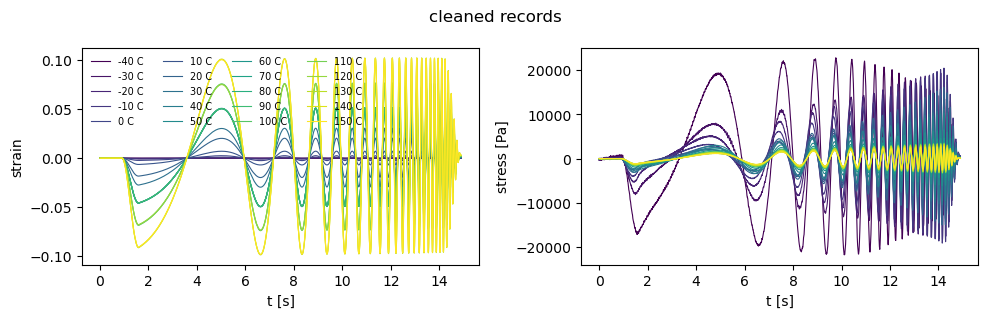

In [29]:
fig0, ax0 = plt.subplots(1, 2, figsize=(10, 3.2))
cmap = plt.get_cmap("viridis")
for i, (T, (t, g, s)) in enumerate(zip(TEMPS, records)):
    col = cmap(i / max(1, len(TEMPS) - 1))
    ax0[0].plot(t, g, lw=0.8, color=col, label=f"{T:g} C")
    ax0[1].plot(t, s, lw=0.8, color=col)
ax0[0].set_xlabel("t [s]"); ax0[0].set_ylabel("strain")
ax0[0].legend(frameon=False, fontsize=7, ncol=min(len(TEMPS), 4))
ax0[1].set_xlabel("t [s]"); ax0[1].set_ylabel("stress [Pa]")
fig0.suptitle("cleaned records"); fig0.tight_layout()
fig0.savefig(f"{OUTDIR}/real_cleaned_records.png", dpi=150)
plt.show()

## 2) AIC/BIC model selection across the full candidate library

Every candidate is fit **jointly to the identical set of records** (same
horizontal-shift parameterization, same number of shift factors), so
`\Delta$BIC`/`\Delta$AIC` differences are attributable to the constitutive
term alone -- see `rheogp/mastercurve.py` and the companion paper's
Eq. (5)/(6) for the exact accounting (`k_total` includes the shared shape
parameters, the shared prefactors, the GP hyperparameters, and the M-1
identifiable shift factors).

  [FractionalZener] step     0 | -ELBO 2.1499 | alpha=0.699  beta=0.299  kappa=0.100  tau_c=1.003 | wait 0
  [FractionalZener] step   200 | -ELBO 1.5861 | alpha=0.567  beta=0.208  kappa=0.287  tau_c=1.404 | wait 0
  [FractionalZener] step   400 | -ELBO 1.3973 | alpha=0.639  beta=0.412  kappa=0.492  tau_c=1.304 | wait 0
  [FractionalZener] step   600 | -ELBO 1.2233 | alpha=0.698  beta=0.563  kappa=0.616  tau_c=1.240 | wait 0
  [FractionalZener] step   800 | -ELBO 1.0495 | alpha=0.654  beta=0.523  kappa=0.567  tau_c=1.136 | wait 0
  [FractionalZener] step  1000 | -ELBO 0.9026 | alpha=0.673  beta=0.425  kappa=0.489  tau_c=0.200 | wait 0
  [FractionalZener] step  1200 | -ELBO 0.7790 | alpha=0.641  beta=0.339  kappa=0.436  tau_c=0.013 | wait 0
  [FractionalZener] step  1400 | -ELBO 0.6571 | alpha=0.613  beta=0.265  kappa=0.400  tau_c=0.001 | wait 0
  [FractionalZener] step  1600 | -ELBO 0.5223 | alpha=0.615  beta=0.195  kappa=0.370  tau_c=0.000 | wait 0
  [FractionalZener] step  1800 | -ELB

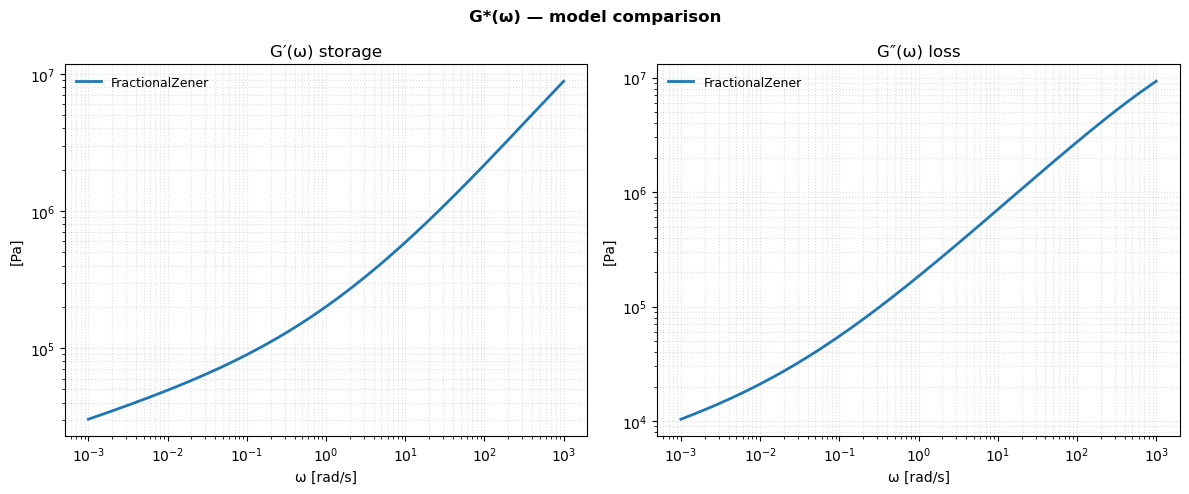


Best model by BIC: FractionalZener

  FractionalZener            BIC=  -283056.57  AIC=  -283344.01  k= 29  R2=0.99138
      shape      : {'alpha': 0.6406091451644897, 'beta': 0.12618975341320038, 'kappa': 0.18084213137626648, 'tau_c': 0.0001000145057332702}
      prefactors : Gc=6.738e+07 [6.725e+07, 6.76e+07]  K=1.057e+05 [1.042e+05, 1.068e+05]


In [30]:
best, curves = compare_master_curve_models(records, TEMPS, CANDIDATE_MODELS,
                                            i_ref=I_REF, criterion=CRITERION,
                                           #noise_model="proportional",
                                           **FITKW)
print(f"\nBest model by {CRITERION.upper()}: {best.model_name}\n")


def _fmt_prefactors(mc):
    """One line per prefactor: posterior mean + 95% credible interval
    (these are GP *sensitivities*, not directly optimized -- see
    `SPGP._extract_prefactors` in rheogp/model.py)."""
    return "  ".join(
        f"{k}={v['scalar_mean']:.4g} [{v['scalar_lower']:.4g}, {v['scalar_upper']:.4g}]"
        for k, v in mc.model_.prefactors_.items()
    )


for name, mc in sorted(curves.items(), key=lambda kv: kv[1].metrics_[CRITERION]):
    m = mc.metrics_
    print(f"  {name:26s} BIC={m['bic']:12.2f}  AIC={m['aic']:12.2f}  "
          f"k={m['n_params']['k_total']:3d}  R2={m['r2']:.5f}")
    print(f"      shape      : {mc.model_.gp_model_.phys.named_phys_params()}")
    print(f"      prefactors : {_fmt_prefactors(mc)}")

## 2b) Prefactors and shape parameters -- every fitted candidate

`compare_master_curve_models` already fits **every** model in
`CANDIDATE_MODELS` jointly (only `CANDIDATE_MODELS` itself controls how
many candidates that is -- uncomment more of the commented-out entries
in the config cell above to actually compare several constitutive laws
in one run of this notebook; right now only one is active, so the
table below has one row). The printout above already includes the
prefactors for every entry in `curves` (not just the winner); the table
below is the same information as a `pandas.DataFrame`, sorted by
`CRITERION`, for easier copy/paste or export.

In [31]:
import pandas as pd

rows = []
for name, mc in curves.items():
    m = mc.metrics_
    shape = mc.model_.gp_model_.phys.named_phys_params()
    row = dict(model=name, bic=m["bic"], aic=m["aic"],
               k=m["n_params"]["k_total"], R2=m["r2"], RMSE=m["rmse"])
    row.update({f"shape:{k}": v for k, v in shape.items()})
    for pf_name, pf in mc.model_.prefactors_.items():
        row[f"prefactor:{pf_name}"] = pf["scalar_mean"]
        row[f"prefactor:{pf_name}_lo"] = pf["scalar_lower"]
        row[f"prefactor:{pf_name}_hi"] = pf["scalar_upper"]
    rows.append(row)

comparison_df = pd.DataFrame(rows).sort_values(CRITERION.lower()).reset_index(drop=True)
comparison_df

,model,bic,aic,k,R2,RMSE,shape:alpha,shape:beta,shape:kappa,shape:tau_c,prefactor:Gc,prefactor:Gc_lo,prefactor:Gc_hi,prefactor:K,prefactor:K_lo,prefactor:K_hi
0,FractionalZener,-283056.57274,-283344.010334,29,0.991379,426.161083,0.640609,0.12619,0.180842,0.0001,6.737600e+07,6.725362e+07,6.760237e+07,105711.270523,104193.996425,106819.375963


## 2c) Monitoring training -- does the ELBO actually converge?

Every candidate's `_train_loop` (`rheogp/model.py`) records the full
per-epoch trace of the negative ELBO (`history_["loss"]`) and of every
shared shape parameter (`history_["params"]`). This is exactly what
`SPGP.plot_convergence()` already knows how to plot for a single-record
fit, and it works unmodified here because `MultiRecordSPGP` is an
`SPGP` subclass with its own `history_` populated the same way.

For every fitted candidate below: the **left** panel is the training
loss (`-ELBO`, lower is better) -- it should flatten out clearly before
training stops. Training stops one of two ways, and the printout tells
you which happened:

* **early-stopped** -- `patience` epochs passed with no improvement
  bigger than `1e-4`, i.e. the optimizer itself decided the loss had
  plateaued. This is the sign of a converged fit.
* **hit the epoch budget** (`n_epochs`) -- training was cut off, not
  because the loss stopped improving, but because the budget ran out.
  If the left panel is still visibly sloping down at the right edge,
  the reported BIC/AIC/prefactors for that candidate should be treated
  as provisional -- re-run with a larger `n_epochs`/`patience` in
  `FITKW` before trusting a model-selection call built on it.

The **right** panel overlays every shared shape parameter (α, β, κ, ...)
against its own trace (τ_c on a secondary axis when present). A
parameter that is still drifting once the loss curve has flattened is
a red flag of its own -- it means the loss surface has a shallow/flat
direction there (e.g. two exponents trading off against each other
while the *fit* stays equally good), so its point estimate is less
trustworthy than the loss curve alone would suggest, even though the
optimizer is technically "converged" in the loss.

FractionalZener: ran 7721/20000 epochs -- early-stopped (loss plateaued)


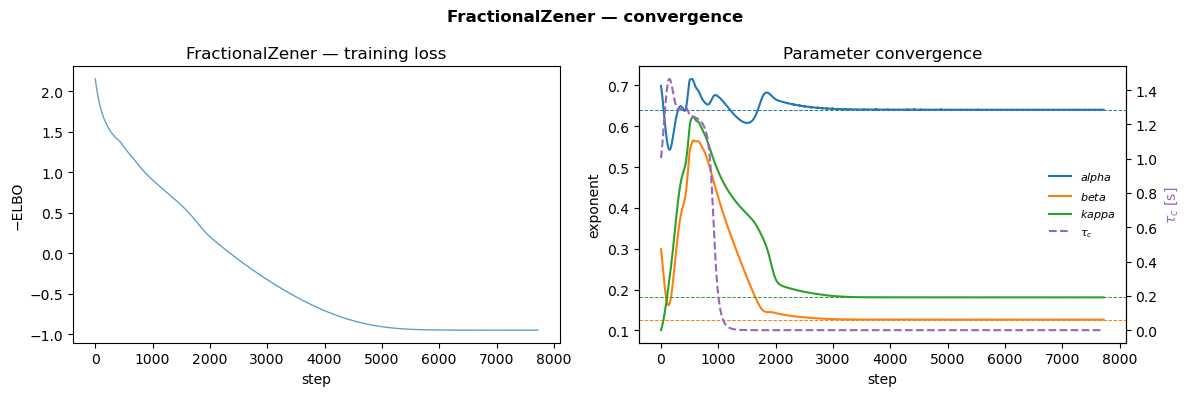

In [32]:
n_budget = FITKW["n_epochs"]   # kernel="linear" -> single-phase training (see SPGP._train)

for name, mc in curves.items():
    hist = mc.model_.history_
    n_ran = len(hist.get("loss", []))
    stopped_early = n_ran < n_budget
    tag = "early-stopped (loss plateaued)" if stopped_early else \
          "HIT THE EPOCH BUDGET -- inspect the curve below before trusting this fit"
    print(f"{name}: ran {n_ran}/{n_budget} epochs -- {tag}")
    mc.model_.plot_convergence()
    plt.show()

## 2d) Effective sample size from residual autocorrelation

`compare_master_curve_models` scores each candidate with
`BIC = 2*NLL + k*ln(N)`, where `N = metrics_["n_data"]` is the RAW
number of time samples pooled across every chirp -- here, on the order
of 30,000 samples/record x 17 records. But adjacent residuals in a
chirp sampled far above the material's own relaxation bandwidth are
nearly the same number repeated, not independent draws, so `N`
overstates how much *independent* evidence backs the fit.

The standard fix (Sokal 1989 -- the same estimator emcee/ArviZ use for
MCMC chains) is to replace `N` by an effective sample size
`N_eff = N / tau_int`, where `tau_int` is the residuals' own integrated
autocorrelation time: `rheogp.utils.effective_sample_size`. Because
autocorrelation only means something *within* one chirp (the residual
at the end of record i says nothing about record i+1, an unrelated
experiment at another temperature), `tau_int`/`N_eff` is computed
**per record and summed** (`effective_sample_size_segments`), never on
the naively concatenated residual vector.

The cell below reports `N`, `N_eff`, mean `tau_int`, the per-point
average -ELBO (`elbo_per_point`), and `k` for every candidate -- the
raw ingredients -- but deliberately does **not** fold these back into
a single BIC(N_eff)/AIC(N_eff) number. How to do that recombination is
a genuine modeling choice, not a settled formula: correcting only the
`k*ln(N)` penalty term (leaving `elbo_per_point * N`, i.e. the ORIGINAL
`nll`, untouched) is one convention; rescaling the likelihood term
itself too (`elbo_per_point * N_eff`, since the per-point average is
only really representative of `N_eff` independent samples in the
first place) is another, more internally-consistent one. Which is
"right" depends on assumptions this notebook shouldn't silently make
for you -- do that arithmetic yourself from the printed numbers.

Model                               N      N_eff  mean tau_int  elbo_per_point    k
FractionalZener                148991     1230.1         487.5       -0.951071   29


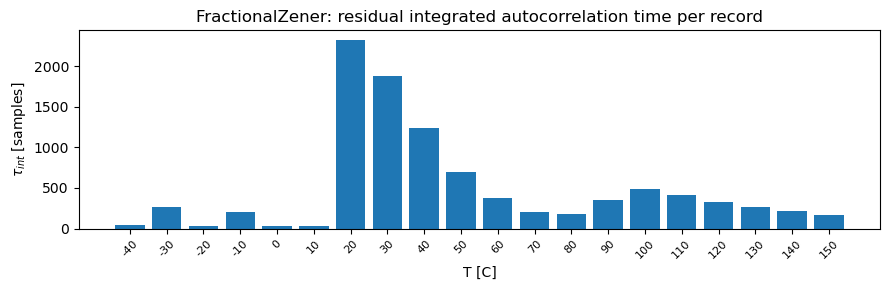

In [33]:
from rheogp.utils import effective_sample_size_segments

print(f"{'Model':<26} {'N':>10} {'N_eff':>10} {'mean tau_int':>13} "
      f"{'elbo_per_point':>15} {'k':>4}")
neff_report = {}
for name, mc in sorted(curves.items(), key=lambda kv: kv[1].metrics_[CRITERION]):
    mj = mc.model_
    residual_segments = [mj.stress_[lo:hi] - mj.pred_[lo:hi] for lo, hi in mj._bounds]
    n_eff, n_raw, per_seg = effective_sample_size_segments(residual_segments)
    m = mc.metrics_
    k = m["n_params"]["k_total"]
    mean_tau = float(np.mean([tau for _, tau, _ in per_seg]))
    neff_report[name] = dict(n_eff=n_eff, n_raw=n_raw, mean_tau=mean_tau,
                              per_record=per_seg)
    print(f"{name:<26} {n_raw:>10d} {n_eff:>10.1f} {mean_tau:>13.1f} "
          f"{m['elbo_per_point']:>15.6g} {k:>4d}")

# Deliberately NOT recombined into a BIC(N_eff)/AIC(N_eff) here -- how to
# fold N_eff back into an information criterion is a modeling choice with
# real ambiguity (does it only correct the k*ln(N) penalty, leaving the
# likelihood term computed under N raw points untouched, or does it also
# rescale the likelihood term itself, elbo_per_point * N_eff, since
# elbo_per_point is only really representative of N_eff independent
# samples?) -- not something to bake into a library function. Everything
# needed to do that arithmetic yourself is in the table above and in
# `neff_report`/`mc.metrics_["elbo_per_point"]`/`mc.metrics_["n_params"]`.

# where (which temperatures) is the autocorrelation worst for the winner?
best_name = min(curves, key=lambda n: curves[n].metrics_[CRITERION])
taus_best = [tau for _, tau, _ in neff_report[best_name]["per_record"]]
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(len(TEMPS)), taus_best, color="tab:blue")
ax.set_xticks(range(len(TEMPS)))
ax.set_xticklabels([f"{T:g}" for T in TEMPS], rotation=45, fontsize=8)
ax.set_xlabel("T [C]"); ax.set_ylabel(r"$\tau_{int}$ [samples]")
ax.set_title(f"{best_name}: residual integrated autocorrelation time per record")
fig.tight_layout()
plt.show()

## How the master curve in the next plot is actually built

The plot below overlays three different objects on the same
reduced-frequency axis; it helps to keep them separate.

**1. The raw, empirical points** -- `MasterCurve.reduced_data()`. For
EACH record `i` separately, `rheogp.mastercurve.fft_transfer` FFTs the
*measured* strain and stress and forms the empirical transfer function
`Y*(ω) = FFT(σ)/FFT(γ)` at that record's own (real, instrument)
frequencies `ω`. Nothing modelled yet -- this is the data, re-expressed
in the frequency domain.

**2. The horizontal shift.** Each record's frequency axis is then
multiplied by that record's own fitted shift factor,
`ω_ref = a_T(T_i) · ω`. Unlike the classical/conventional TTS recipe
(slide spectra until they visually overlap -- see
`05_conventional_master_curve_fft.ipynb`), `a_T` here is **one of the
trainable parameters of the very same joint fit** as the shape
parameters and prefactors (`phys.log_aT` in
`rheogp.rheogp_multi.shift_kernel_class`), recovered by maximizing the
same ELBO -- simultaneously, not as a separate post-processing step
after the physics is fit. Because every record uses the same `a_T` in
both the time-domain fit *and* this frequency-domain re-expression,
points from every temperature collapse onto ONE curve in `ω_ref` if
(and only if) the material is thermorheologically simple (one
horizontal shift, no vertical rescale -- see the module docstring of
`rheogp.mastercurve`) and the chosen constitutive law is the right one.

**3. The model's own analytic curve** -- `best.model_curve()`. This is
**not** an FFT of anything. It is the constitutive law's closed-form
`G'(ω)`, `G''(ω)` (`phys.Gstar(omega, prefactors)`), evaluated at the
REFERENCE temperature only, using:
  - the shared shape parameters (α, β, κ, τ_c -- whichever the chosen
    law has), read off `phys.named_phys_params()`;
  - the shared prefactors (𝕍, 𝔾, G_c, ...) -- **not** optimized
    directly, but recovered as GP *sensitivities*,
    `∂(predicted stress)/∂(physical feature)`, sampled from the
    trained variational posterior and averaged over time
    (`SPGP._extract_prefactors` in `rheogp/model.py`); this is why
    each prefactor carries a credible interval rather than being a
    single number.

Because `Gstar` is a genuine closed-form function of ω, it can be
evaluated at ANY ω -- including frequencies far outside what any
single chirp in `records` ever measured -- extrapolating the fitted
physics the way a fitted algebraic formula extrapolates, not the way a
nonparametric curve (a bare GP over ω, or a spline through the FFT
points) is restricted to interpolating between observations.

The credible **band** around that curve (`Gp_ci`/`Gdp_ci`) comes from
propagating the POSTERIOR PREFACTOR samples -- not the raw data --
through that same closed-form `Gstar`
(`mastercurve._posterior_scalar_draws`): draw one scalar prefactor per
posterior sample, evaluate `Gstar` at every ω for every draw, and take
the 2.5/97.5 percentile at each ω. No repeated FFTs or Monte-Carlo
re-fitting are needed for this, because shift -> prefactor -> Gstar is
differentiable/analytic end to end.

**So:** the final plot overlays (2) the shifted raw data -- what the
instrument actually measured, in 17 disjoint frequency windows,
stitched together purely by the fitted `a_T`'s -- against (3) one
continuous model line, which is the SAME physics regardless of which
`ω_ref` you are looking at. Where (2) and (3) disagree systematically
at some `ω_ref`, that is model misspecification, not shift-factor
error -- the shift only moves points left/right along the ω axis, it
cannot change their vertical G'/G'' value.

## 3) WLF regression and master curve for the winning model

  MasterCurve  —  FractionalZener  (20 records, T_ref = 10)
  shared shape parameters
    alpha      = 0.640609
    beta       = 0.12619
    kappa      = 0.180842
    tau_c      = 0.000100015
  shared prefactors
    Gc         = 6.7376e+07  [6.72536e+07, 6.76024e+07]
    K          = 105711  [104194, 106819]

  RMSE = 426.161   R2 = 0.991379   AIC = -283344.0   BIC = -283056.6   k = 29

  shift factors a_T (aT[i_ref] = 1 by construction)
    T =   -40.00    a_T = 5.49073e+07
    T =   -30.00    a_T = 158161
    T =   -20.00    a_T = 1225.49
    T =   -10.00    a_T = 57.5839
    T =     0.00    a_T = 5.87641
    T =    10.00    a_T = 1
    T =    20.00    a_T = 0.167171
    T =    30.00    a_T = 0.0396378
    T =    40.00    a_T = 0.0113151
    T =    50.00    a_T = 0.00379703
    T =    60.00    a_T = 0.00153155
    T =    70.00    a_T = 0.00072216
    T =    80.00    a_T = 0.000373408
    T =    90.00    a_T = 0.000200729
    T =   100.00    a_T = 0.000109248
    T =   110.00    a_T =

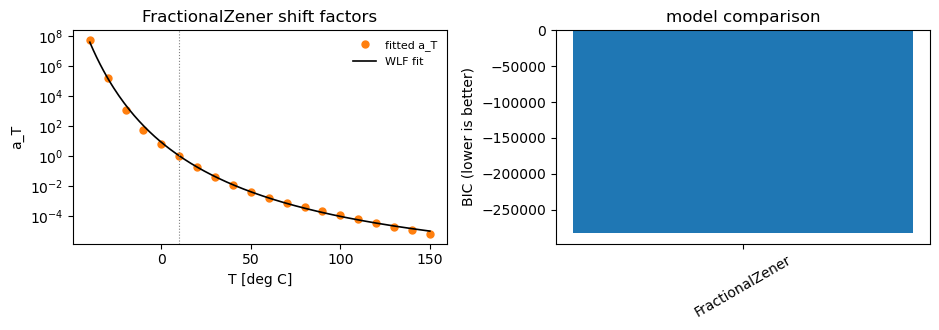

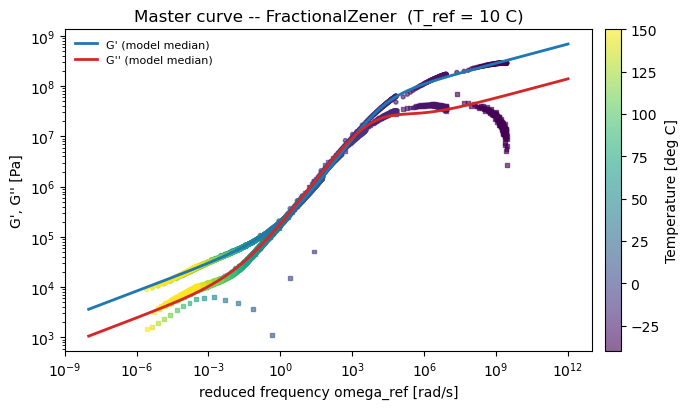

In [34]:
best.fit_wlf()
print(best.summary())

aT_fit = best.aT_
cmap = plt.get_cmap("viridis")
fig1, ax1 = plt.subplots(1, 2, figsize=(9.5, 3.4))
Tv = np.array(best.temperatures)
ax1[0].semilogy(Tv, best.aT_, "o", ms=5, color="tab:orange", label="fitted a_T")
T_fine = np.linspace(Tv.min(), Tv.max(), 200)
ax1[0].semilogy(T_fine, best.predict_aT(T_fine), "k-", lw=1.2, label="WLF fit")
ax1[0].axvline(best.T_ref, color="gray", lw=0.8, ls=":")
ax1[0].set_xlabel("T [deg C]"); ax1[0].set_ylabel("a_T")
ax1[0].set_title(f"{best.model_name} shift factors")
ax1[0].legend(frameon=False, fontsize=8)

for name, mc in curves.items():
    ax1[1].bar(name, mc.metrics_[CRITERION])
ax1[1].set_ylabel(CRITERION.upper() + " (lower is better)")
ax1[1].set_title("model comparison")
ax1[1].tick_params(axis="x", rotation=30)
fig1.tight_layout()
fig1.savefig(f"{OUTDIR}/fig_tts_real_comparison.png", dpi=150)
plt.show()

fig2, ax2 = plt.subplots(1, 1, figsize=(7.2, 4.2))
omega_ref, Gstar, rec_idx = best.reduced_data()
norm = plt.Normalize(vmin=min(best.temperatures), vmax=max(best.temperatures))
T_of_point = np.array(best.temperatures)[rec_idx]
sc1 = ax2.scatter(omega_ref, np.real(Gstar), c=T_of_point, cmap=cmap, norm=norm,
                   s=8, alpha=0.6, marker="o")
ax2.scatter(omega_ref, np.imag(Gstar), c=T_of_point, cmap=cmap, norm=norm,
            s=8, alpha=0.6, marker="s")
ax2.set_xscale("log"); ax2.set_yscale("log")
omega, Gp, Gdp, Gp_ci, Gdp_ci = best.model_curve()
ax2.fill_between(omega, Gp_ci[0], Gp_ci[1], color="tab:blue", alpha=0.15)
ax2.plot(omega, Gp, color="tab:blue", lw=2.0, label="G' (model median)")
ax2.fill_between(omega, Gdp_ci[0], Gdp_ci[1], color="tab:red", alpha=0.15)
ax2.plot(omega, Gdp, color="tab:red", lw=2.0, label="G'' (model median)")
ax2.set_xlabel("reduced frequency omega_ref [rad/s]")
ax2.set_ylabel("G', G'' [Pa]")
ax2.set_title(f"Master curve -- {best.model_name}  (T_ref = {best.T_ref:g} C)")
ax2.legend(frameon=False, fontsize=8, loc="best")
cb = fig2.colorbar(sc1, ax=ax2, pad=0.02); cb.set_label("Temperature [deg C]")
fig2.tight_layout()
fig2.savefig(f"{OUTDIR}/fig_tts_real.pdf", bbox_inches="tight")
fig2.savefig(f"{OUTDIR}/fig_tts_real.png", dpi=300, bbox_inches="tight")
plt.show()

  MasterCurve  —  FractionalZener  (20 records, T_ref = 10)
  shared shape parameters
    alpha      = 0.640609
    beta       = 0.12619
    kappa      = 0.180842
    tau_c      = 0.000100015
  shared prefactors
    Gc         = 6.7376e+07  [6.72536e+07, 6.76024e+07]
    K          = 105711  [104194, 106819]

  RMSE = 426.161   R2 = 0.991379   AIC = -283344.0   BIC = -283056.6   k = 29

  shift factors a_T (aT[i_ref] = 1 by construction)
    T =   -40.00    a_T = 5.49073e+07
    T =   -30.00    a_T = 158161
    T =   -20.00    a_T = 1225.49
    T =   -10.00    a_T = 57.5839
    T =     0.00    a_T = 5.87641
    T =    10.00    a_T = 1
    T =    20.00    a_T = 0.167171
    T =    30.00    a_T = 0.0396378
    T =    40.00    a_T = 0.0113151
    T =    50.00    a_T = 0.00379703
    T =    60.00    a_T = 0.00153155
    T =    70.00    a_T = 0.00072216
    T =    80.00    a_T = 0.000373408
    T =    90.00    a_T = 0.000200729
    T =   100.00    a_T = 0.000109248
    T =   110.00    a_T =

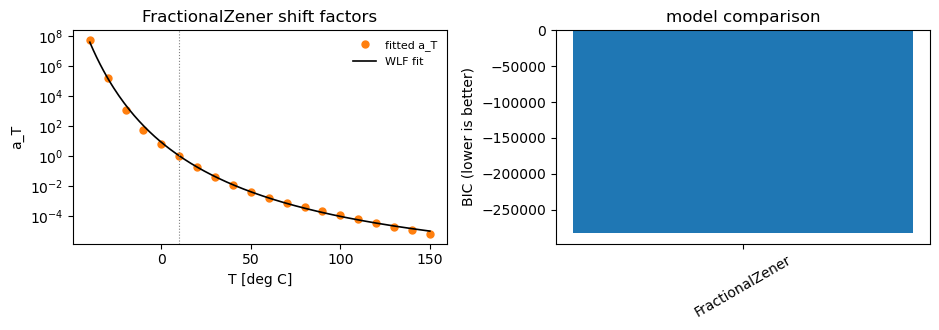

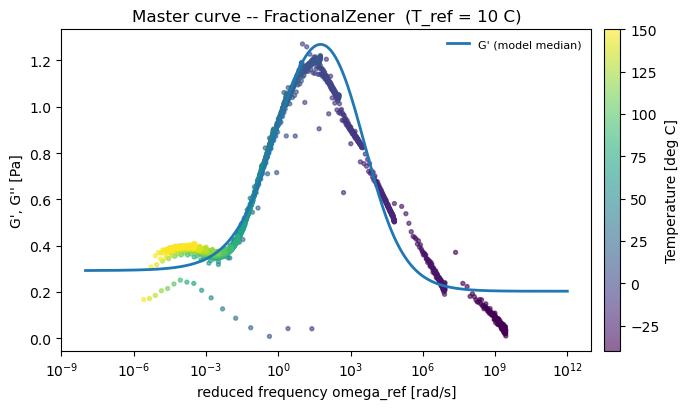

In [35]:
best.fit_wlf()
print(best.summary())

aT_fit = best.aT_
cmap = plt.get_cmap("viridis")
fig1, ax1 = plt.subplots(1, 2, figsize=(9.5, 3.4))
Tv = np.array(best.temperatures)
ax1[0].semilogy(Tv, best.aT_, "o", ms=5, color="tab:orange", label="fitted a_T")
T_fine = np.linspace(Tv.min(), Tv.max(), 200)
ax1[0].semilogy(T_fine, best.predict_aT(T_fine), "k-", lw=1.2, label="WLF fit")
ax1[0].axvline(best.T_ref, color="gray", lw=0.8, ls=":")
ax1[0].set_xlabel("T [deg C]"); ax1[0].set_ylabel("a_T")
ax1[0].set_title(f"{best.model_name} shift factors")
ax1[0].legend(frameon=False, fontsize=8)

for name, mc in curves.items():
    ax1[1].bar(name, mc.metrics_[CRITERION])
ax1[1].set_ylabel(CRITERION.upper() + " (lower is better)")
ax1[1].set_title("model comparison")
ax1[1].tick_params(axis="x", rotation=30)
fig1.tight_layout()
fig1.savefig(f"{OUTDIR}/fig_tts_real_comparison.png", dpi=150)
plt.show()

fig2, ax2 = plt.subplots(1, 1, figsize=(7.2, 4.2))
omega_ref, Gstar, rec_idx = best.reduced_data()
norm = plt.Normalize(vmin=min(best.temperatures), vmax=max(best.temperatures))
T_of_point = np.array(best.temperatures)[rec_idx]
sc1 = ax2.scatter(omega_ref, np.imag(Gstar)/np.real(Gstar), c=T_of_point, cmap=cmap, norm=norm,
                   s=8, alpha=0.6, marker="o")
#ax2.scatter(omega_ref, np.imag(Gstar), c=T_of_point, cmap=cmap, norm=norm,
#            s=8, alpha=0.6, marker="s")
ax2.set_xscale("log"); ax2.set_yscale("linear")
omega, Gp, Gdp, Gp_ci, Gdp_ci = best.model_curve()
#ax2.fill_between(omega, Gp_ci[0], Gp_ci[1], color="tab:blue", alpha=0.15)
ax2.plot(omega, Gdp/Gp, color="tab:blue", lw=2.0, label="G' (model median)")
#ax2.fill_between(omega, Gdp_ci[0], Gdp_ci[1], color="tab:red", alpha=0.15)
#ax2.plot(omega, Gdp, color="tab:red", lw=2.0, label="G'' (model median)")
ax2.set_xlabel("reduced frequency omega_ref [rad/s]")
ax2.set_ylabel("G', G'' [Pa]")
ax2.set_title(f"Master curve -- {best.model_name}  (T_ref = {best.T_ref:g} C)")
ax2.legend(frameon=False, fontsize=8, loc="best")
cb = fig2.colorbar(sc1, ax=ax2, pad=0.02); cb.set_label("Temperature [deg C]")
fig2.tight_layout()
fig2.savefig(f"{OUTDIR}/fig_tts_real.pdf", bbox_inches="tight")
fig2.savefig(f"{OUTDIR}/fig_tts_real.png", dpi=300, bbox_inches="tight")
plt.show()

  MasterCurve  —  FractionalZener  (20 records, T_ref = 10)
  shared shape parameters
    alpha      = 0.640609
    beta       = 0.12619
    kappa      = 0.180842
    tau_c      = 0.000100015
  shared prefactors
    Gc         = 6.7376e+07  [6.72536e+07, 6.76024e+07]
    K          = 105711  [104194, 106819]

  RMSE = 426.161   R2 = 0.991379   AIC = -283344.0   BIC = -283056.6   k = 29

  shift factors a_T (aT[i_ref] = 1 by construction)
    T =   -40.00    a_T = 5.49073e+07
    T =   -30.00    a_T = 158161
    T =   -20.00    a_T = 1225.49
    T =   -10.00    a_T = 57.5839
    T =     0.00    a_T = 5.87641
    T =    10.00    a_T = 1
    T =    20.00    a_T = 0.167171
    T =    30.00    a_T = 0.0396378
    T =    40.00    a_T = 0.0113151
    T =    50.00    a_T = 0.00379703
    T =    60.00    a_T = 0.00153155
    T =    70.00    a_T = 0.00072216
    T =    80.00    a_T = 0.000373408
    T =    90.00    a_T = 0.000200729
    T =   100.00    a_T = 0.000109248
    T =   110.00    a_T =

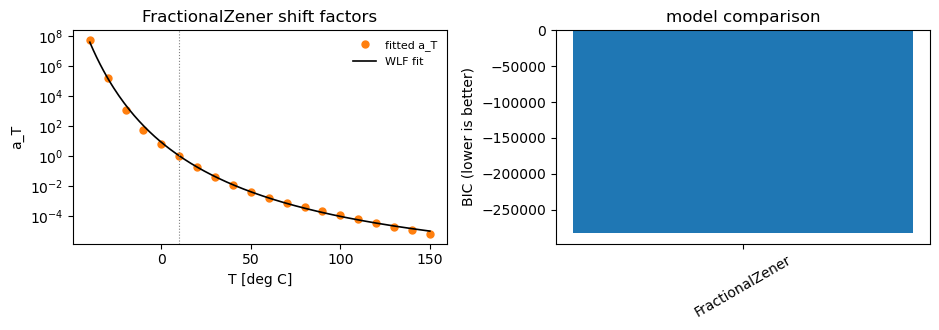

/appl/scibuilder-mamba/aalto-rhel9/prod/software/scicomp-python-env/2025.2/b4b5f8e/lib/python3.12/site-packages/matplotlib/cbook.py:1719: ComplexWarning: Casting complex values to real discards the imaginary part
  return math.isfinite(val)
/appl/scibuilder-mamba/aalto-rhel9/prod/software/scicomp-python-env/2025.2/b4b5f8e/lib/python3.12/site-packages/matplotlib/collections.py:200: ComplexWarning: Casting complex values to real discards the imaginary part
  offsets = np.asanyarray(offsets, float)


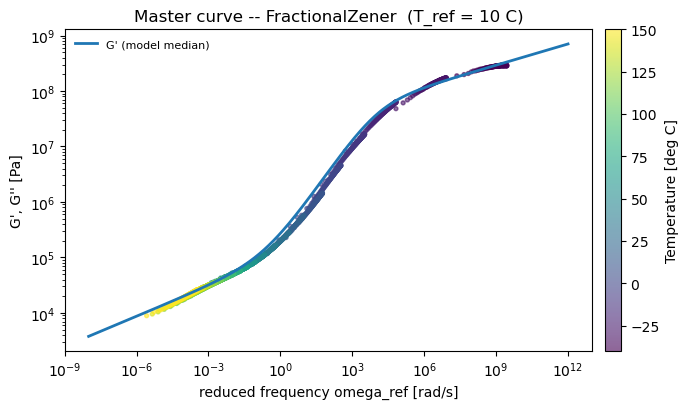

In [36]:
best.fit_wlf()
print(best.summary())

aT_fit = best.aT_
cmap = plt.get_cmap("viridis")
fig1, ax1 = plt.subplots(1, 2, figsize=(9.5, 3.4))
Tv = np.array(best.temperatures)
ax1[0].semilogy(Tv, best.aT_, "o", ms=5, color="tab:orange", label="fitted a_T")
T_fine = np.linspace(Tv.min(), Tv.max(), 200)
ax1[0].semilogy(T_fine, best.predict_aT(T_fine), "k-", lw=1.2, label="WLF fit")
ax1[0].axvline(best.T_ref, color="gray", lw=0.8, ls=":")
ax1[0].set_xlabel("T [deg C]"); ax1[0].set_ylabel("a_T")
ax1[0].set_title(f"{best.model_name} shift factors")
ax1[0].legend(frameon=False, fontsize=8)

for name, mc in curves.items():
    ax1[1].bar(name, mc.metrics_[CRITERION])
ax1[1].set_ylabel(CRITERION.upper() + " (lower is better)")
ax1[1].set_title("model comparison")
ax1[1].tick_params(axis="x", rotation=30)
fig1.tight_layout()
fig1.savefig(f"{OUTDIR}/fig_tts_real_comparison.png", dpi=150)
plt.show()

fig2, ax2 = plt.subplots(1, 1, figsize=(7.2, 4.2))
omega_ref, Gstar, rec_idx = best.reduced_data()
norm = plt.Normalize(vmin=min(best.temperatures), vmax=max(best.temperatures))
T_of_point = np.array(best.temperatures)[rec_idx]
sc1 = ax2.scatter(omega_ref, Gstar, c=T_of_point, cmap=cmap, norm=norm,
                   s=8, alpha=0.6, marker="o")
#ax2.scatter(omega_ref, np.imag(Gstar), c=T_of_point, cmap=cmap, norm=norm,
#            s=8, alpha=0.6, marker="s")
ax2.set_xscale("log"); ax2.set_yscale("log")
omega, Gp, Gdp, Gp_ci, Gdp_ci = best.model_curve()
#ax2.fill_between(omega, Gp_ci[0], Gp_ci[1], color="tab:blue", alpha=0.15)
ax2.plot(omega, np.sqrt(Gp**2 + Gdp**2), color="tab:blue", lw=2.0, label="G' (model median)")
#ax2.fill_between(omega, Gdp_ci[0], Gdp_ci[1], color="tab:red", alpha=0.15)
#ax2.plot(omega, Gdp, color="tab:red", lw=2.0, label="G'' (model median)")
ax2.set_xlabel("reduced frequency omega_ref [rad/s]")
ax2.set_ylabel("G', G'' [Pa]")
ax2.set_title(f"Master curve -- {best.model_name}  (T_ref = {best.T_ref:g} C)")
ax2.legend(frameon=False, fontsize=8, loc="best")
cb = fig2.colorbar(sc1, ax=ax2, pad=0.02); cb.set_label("Temperature [deg C]")
fig2.tight_layout()
fig2.savefig(f"{OUTDIR}/fig_tts_real.pdf", bbox_inches="tight")
fig2.savefig(f"{OUTDIR}/fig_tts_real.png", dpi=300, bbox_inches="tight")
plt.show()

## 3b) Per-record stress fit + residuals -- every temperature

The pooled RMSE/R² in `best.summary()` can hide a fit that is
excellent at some temperatures and poor at others (e.g. a record whose
own frequency window falls right on the crossover, vs. one that only
sees a single asymptote). One panel per record below, fit on top,
residual directly underneath on the SAME time axis -- so a
systematic (non-random) pattern in a residual panel is easy to spot
record-by-record, not just in aggregate.

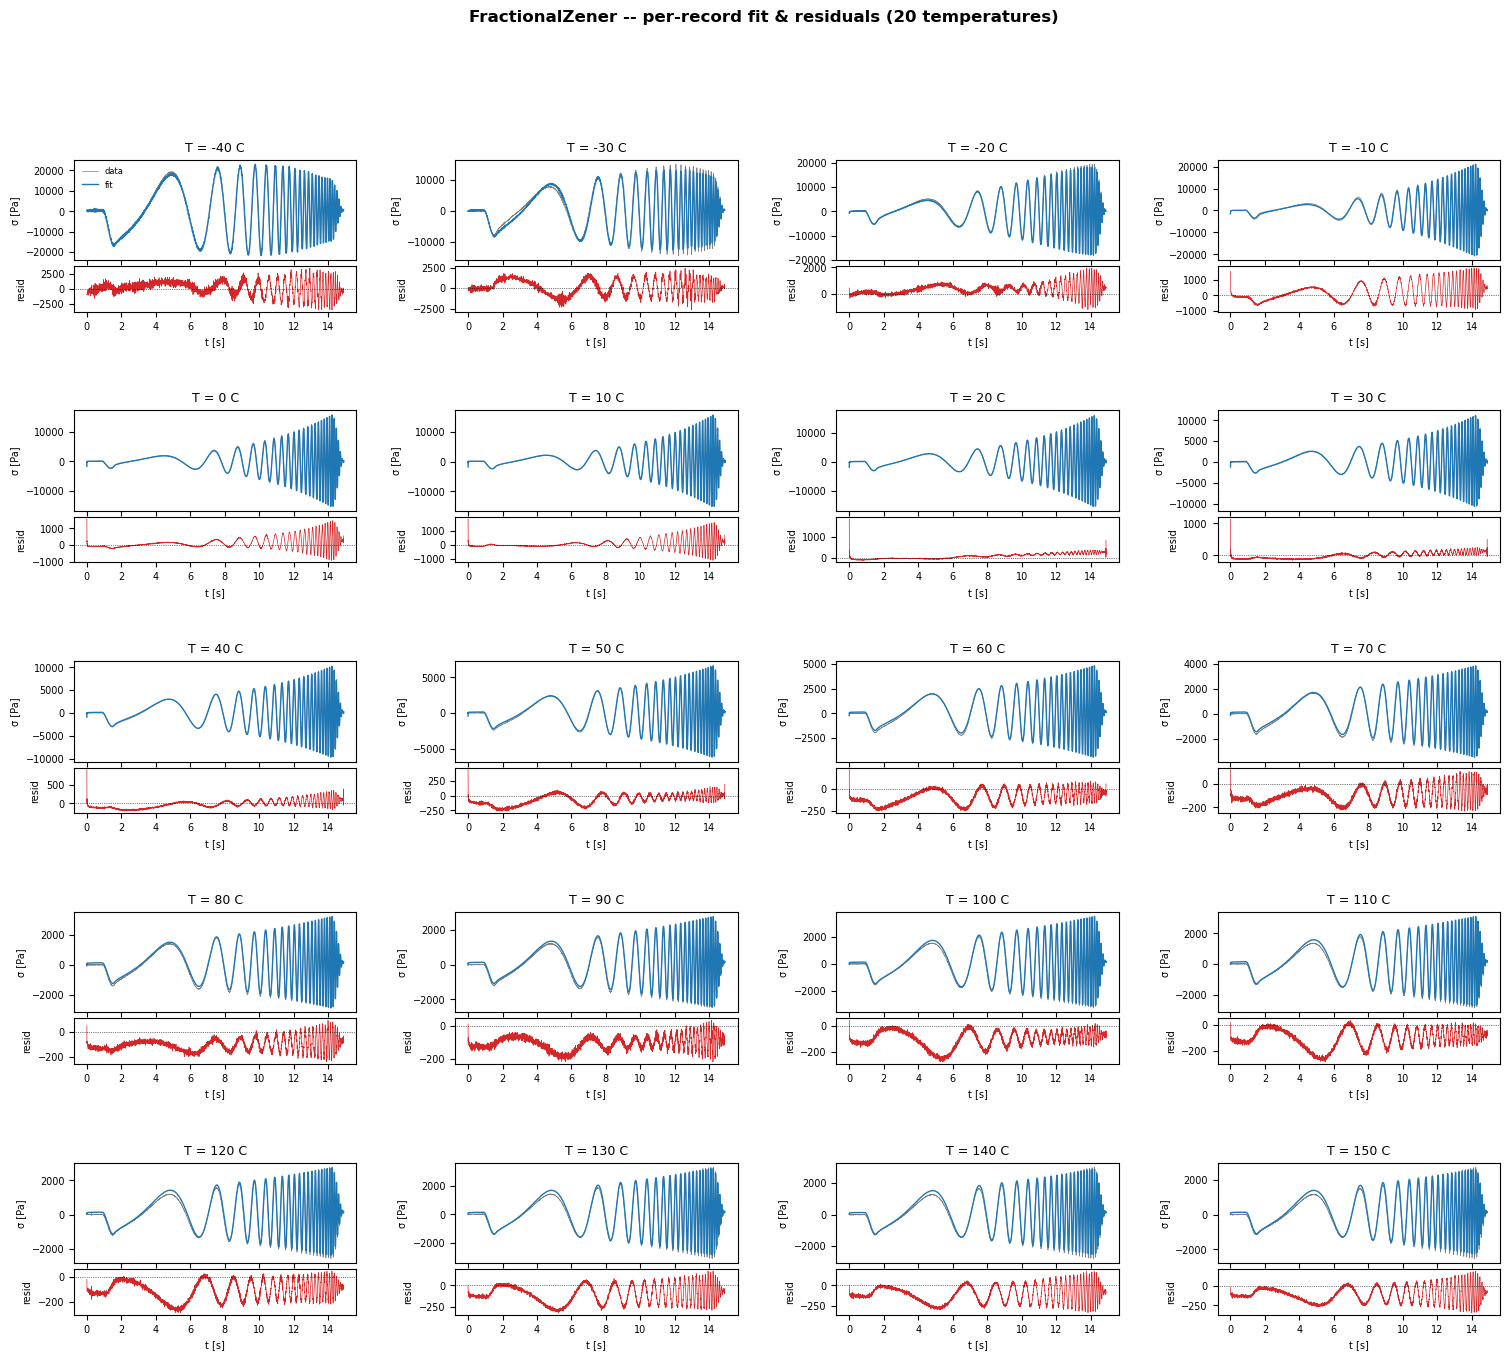

In [37]:
mj = best.model_
n_rec = len(TEMPS)
ncols = 4
nrows = int(np.ceil(n_rec / ncols))
fig = plt.figure(figsize=(4.6 * ncols, 3.0 * nrows))
outer = fig.add_gridspec(nrows, ncols, hspace=0.65, wspace=0.35)

for i, (T, (t, g, s)) in enumerate(zip(TEMPS, records)):
    r, c = divmod(i, ncols)
    inner = outer[r, c].subgridspec(2, 1, height_ratios=[2.2, 1], hspace=0.08)
    ax_fit = fig.add_subplot(inner[0])
    ax_res = fig.add_subplot(inner[1], sharex=ax_fit)

    lo, hi = mj._bounds[i]
    pred_i = mj.pred_[lo:hi]
    resid_i = s - pred_i

    ax_fit.plot(t, s, color="black", lw=0.5, alpha=0.5, label="data")
    ax_fit.plot(t, pred_i, color="tab:blue", lw=1.0, label="fit")
    ax_fit.set_title(f"T = {T:g} C", fontsize=9)
    ax_fit.tick_params(labelbottom=False, labelsize=7)
    ax_fit.set_ylabel("σ [Pa]", fontsize=7)
    if i == 0:
        ax_fit.legend(fontsize=6, frameon=False)

    ax_res.plot(t, resid_i, color="tab:red", lw=0.5)
    ax_res.axhline(0, color="black", lw=0.5, ls=":")
    ax_res.set_ylabel("resid", fontsize=7)
    ax_res.set_xlabel("t [s]", fontsize=7)
    ax_res.tick_params(labelsize=7)

fig.suptitle(f"{best.model_name} -- per-record fit & residuals "
             f"({n_rec} temperatures)", fontweight="bold")
fig.savefig(f"{OUTDIR}/fig_tts_real_panel_perrecord.png", dpi=150, bbox_inches="tight")
plt.show()

## 4) Export LaTeX macros + model-comparison table for `main.tex`

In [38]:
metrics = best.metrics_
pj = best.model_.gp_model_.phys.named_phys_params()
wlf = best.wlf_

macros = dict(
    realNTemps=len(TEMPS), realTempMin=f"{min(TEMPS):g}", realTempMax=f"{max(TEMPS):g}",
    realTempRef=f"{best.T_ref:g}",
    realBestModel=best.model_name,
    realRMSE=f"{metrics['rmse']:.4g}", realRsq=f"{metrics['r2']:.6f}",
    realBIC=f"{metrics['bic']:.1f}", realAIC=f"{metrics['aic']:.1f}",
    realKTotal=metrics["n_params"]["k_total"], realNShift=metrics["n_params"]["n_shift"],
    realNData=metrics["n_data"],
    realWLFCOneFit=f"{wlf['C1']:.3f}", realWLFCOneSD=f"{wlf['C1_std']:.3f}",
    realWLFCTwoFit=f"{wlf['C2']:.2f}", realWLFCTwoSD=f"{wlf['C2_std']:.2f}",
)
# runner-up gap, for "decisively/marginally preferred" language in the text
ranked = sorted(curves.items(), key=lambda kv: kv[1].metrics_[CRITERION])
if len(ranked) > 1:
    macros["realRunnerUp"] = ranked[1][0]
    macros["realDeltaBICRunnerUp"] = f"{ranked[1][1].metrics_['bic'] - metrics['bic']:.1f}"
write_macros(f"{OUTDIR}/results_real.tex", macros)

table_src = model_comparison_latex_table(
    curves, criterion=CRITERION,
    caption=(f"Model comparison for the real chirp dataset, \\realNTemps\\ "
             "records at temperatures spanning \\realTempMin--\\realTempMax"
             "$^\\circ$C, fit jointly ($N=$\\realNData). Lower $\\Delta$" +
             CRITERION.upper() + " is better; $\\Delta=0$ marks the selected model."),
    label="tab:real_ic",
)
write_table(f"{OUTDIR}/table_real.tex", table_src)
print(table_src)

wrote 16 macros -> owchirp_fzm_out/results_real.tex
wrote table -> owchirp_fzm_out/table_real.tex
\begin{table*}[t]
  \centering
  \caption{Model comparison for the real chirp dataset, \realNTemps\ records at temperatures spanning \realTempMin--\realTempMax$^\circ$C, fit jointly ($N=$\realNData). Lower $\Delta$BIC is better; $\Delta=0$ marks the selected model.}
  \label{tab:real_ic}
  \small
  \setlength{\tabcolsep}{4pt}
  \renewcommand{\arraystretch}{1.2}
  \begin{tabular}{lcccccccccccc}
    \hline
    Model & $2\mathcal{U}$ & $2k$ & $k\ln N$ & AIC & BIC & $\Delta$BIC & RMSE [Pa] & $R^2$ & $\alpha$ & $\beta$ & $\kappa$ & $\tau_{c}$ \\
    \hline
    FractionalZener & -283402 & 58 & 345.44 & -283344 & -283057 & 0 & 426.2 & 0.9914 & 0.641 & 0.126 & 0.181 & 0.0001 \\
    \hline
  \end{tabular}
\end{table*}


## 5) Export the full dataset for replotting elsewhere (scienceplots, etc.)

In [39]:
from paper_utils import export_master_curve

export_master_curve(
    f"{OUTDIR}/{DATASET}_export_fzm", best.model_, records, TEMPS, I_REF,
    wlf=wlf,
)
# See notebook 01's export cell for the full list of what
# load_master_curve_export("real_export") returns on another machine --
# identical schema; this dataset has no `truth`/`shift_factors_truth`
# (real data, ground truth unknown), and `d.meta["model_name"]` is
# whichever candidate BIC selected (see Sec. 2 above).

exported 20 records -> owchirp_fzm_out/owchirp_export_fzm.npz + owchirp_fzm_out/owchirp_export_fzm.json


('owchirp_fzm_out/owchirp_export_fzm.npz',
 'owchirp_fzm_out/owchirp_export_fzm.json')

## 6) Export the candidate comparison for the plotting notebook

`export_master_curve()` above saves the winning fit. This saves what every
candidate scored and recovered -- information criteria under the raw $N$ and
both $N_\mathrm{eff}$ conventions, parameter counts, recovered parameters,
inferred observation noise and convergence -- which is what
`fzm_dgeba.ipynb` reads to draw the model-selection figure.

In [40]:
from paper_utils import export_model_comparison

# The per-candidate comparison itself, not just the winner's master
# curve. `export_master_curve` above writes the WINNING fit; this writes
# what every candidate scored and recovered, so `fzm_dgeba.ipynb` can
# draw the model-selection figure without refitting a thing.
#
# Includes, per candidate: AIC and BIC on the raw N, both N_eff-corrected
# BIC conventions (the arithmetic Sec. 2d deliberately left un-baked, done
# here explicitly rather than hidden in a library default), N_eff and the
# per-record integrated autocorrelation time behind it, the recovered
# shape parameters and prefactors, the shift factors, the observation
# noise the GP inferred, and whether the fit early-stopped or hit its
# epoch budget.
export_model_comparison(
    f"{OUTDIR}/{DATASET}_model_comparison", curves,
    temps=TEMPS, i_ref=I_REF,
    n_epochs_budget=FITKW["n_epochs"],
    extra=dict(dataset=DATASET, criterion=CRITERION,
               data_glob=DATA_GLOB,
               master_curve_export=f"{OUTDIR}/{DATASET}_export_fzm"),
)
# Reload anywhere with only numpy/json installed:
#   from paper_utils import load_model_comparison
#   d = load_model_comparison("DGEBA-IPD_model_comparison")
#   d.candidates                -> the candidate names that were fitted
#   d.winners["bic_raw"]        -> winner under each criterion
#   d.delta["bic_raw"][name]    -> that candidate's gap to the winner
#   d.results[name]["params"]   -> what that candidate actually recovered
#   d.results[name]["n_eff"], ["mean_tau_int"], ["noise_sd_inferred"],
#   d.results[name]["n_epochs_ran"], ["early_stopped"]

exported 1 candidate(s) -> owchirp_fzm_out/owchirp_model_comparison.json + owchirp_fzm_out/owchirp_model_comparison_models.csv


('owchirp_fzm_out/owchirp_model_comparison.json',
 'owchirp_fzm_out/owchirp_model_comparison_models.csv')

## 3c) If one chirp spanned the whole master-curve frequency range, would it predict the master curve?

**Short answer: yes, in principle -- with no temperature superposition
needed at all -- but only under conditions no real single experiment
can satisfy, which is exactly WHY the 17-temperature pipeline above
exists instead.**

*Why "yes, in principle":* Section "How the master curve is actually
built" above established that `Gstar(ω)` is a genuine closed-form
function of ω, not a black box restricted to interpolating between the
frequencies any one chirp happened to see. If you had ONE chirp, run at
`T_ref` alone, that swept every ω the combined master curve covers,
with (a) enough duration to contain several full cycles at the
SLOWEST frequency in that sweep, (b) a sample rate fast enough for the
FASTEST frequency, and (c) adequate strain amplitude/SNR everywhere in
between (what `fft_transfer`'s `min_snr_db` gate checks) -- fitting the
SAME constitutive law to that ONE record with a plain, single-record
`SPGP` (no `a_T`, no joint fit) would recover the same shape parameters
and prefactors. It is the identical physics; TTS is not required by
the constitutive law, only by the instrument.

*Why real instruments don't do this:* the code cell below computes the
actual reduced-frequency range this dataset's 17 chirps cover
(`best.reduced_data()`), and how long a single chirp / how high a
sample rate would need to be to reach both ends of it directly, at one
temperature. That number is the whole reason TTS trades temperature
for frequency instead of brute-forcing bandwidth.

*The experiment below* is a **self-consistency check**, not new
experimental validation (it cannot be -- this notebook has no
instrument that can run a multi-decade single-temperature chirp): it
synthesizes ONE broadband chirp at `T_ref`, using the WINNING model's
OWN recovered physics as the ground truth, over as much of the real
instrument's sample rate / a longer-than-actual duration as is
tractable to fit here (letting the *same* rheometer run several times
longer at *one* temperature, instead of 17 short chirps at 17
temperatures) -- then fits a fresh, single-record `SPGP` to it and
overlays the result on the 17-chirp master curve. If the physics is
self-consistent, the two curves should coincide over the sub-range the
synthetic chirp can actually reach; how much of the FULL master-curve
range that sub-range fails to cover is itself the answer to "how is it
doing" for a single-chirp alternative.

Master curve reduced-frequency coverage: 2.63e-06 - 2.8e+09 rad/s (15.0 decades), achieved by combining 20 chirps at -40-150 C.
A single chirp covering that SAME range alone, at T_ref, would need ~4.78e+06 s duration (~55 days) and a sample rate above ~4.46e+08 Hz throughout -- ~1.28e+16 samples in one record. That is why TTS trades temperature for frequency instead of brute-forcing bandwidth.

One chirp at the real dt=0.002 s, run 6x longer (89.4 s) than an actual record, reaches 0.141 - 1.57e+03 rad/s (4.0 of the 15.0 decades the full 17-chirp master curve covers).

Synthetic broadband chirp: 44,694 samples, dt=0.002 s, duration=89.4 s, sweeping 0.141-1.57e+03 rad/s in ONE record.
  [FractionalZener] step     0 | -ELBO 2.1497 | alpha=0.710  beta=0.313  kappa=0.105  tau_c=0.969 | wait 0
  [FractionalZener] step   200 | -ELBO -2.6408 | alpha=0.918  beta=0.398  kappa=0.428  tau_c=0.003 | wait 2
  [FractionalZener] step   400 | -ELBO -2.7778 | alpha=0.857  beta=0.332  kappa=0.447  tau_c=

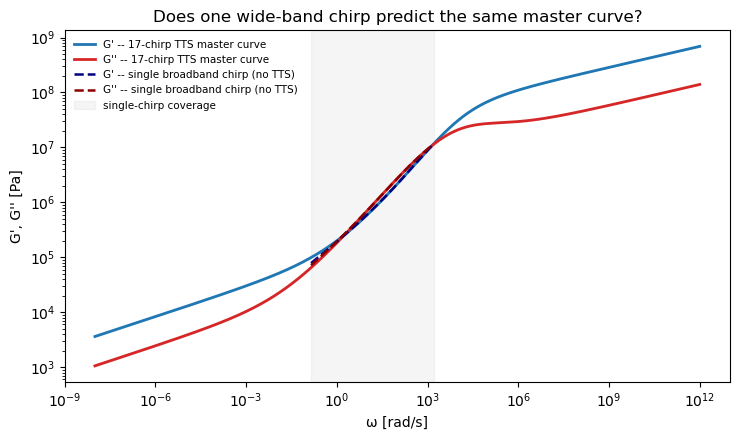

  RheoGP  —  FractionalZener
  Control        : strain-controlled (relaxation representation)
  Convolution    : steady  (from -inf, periodic)
  GP kernel      : linear
  Training mode  : single-phase
  Inducing pts   : 250

  Learned shape parameters
  ------------------------
    alpha      = 0.782807
    beta       = 0.276508
    kappa      = 0.427100
    tau_c      = 0.000650

  Prefactors / sensitivities  (mean  [95% CI])
  --------------------------------------------
    Gc       =  2.03328e+07  [ 2.02863e+07,  2.03921e+07]
    K        =       217385  [      216917,       217853]

  Derived physical parameters
  ---------------------------
    tau_c      = 0.000650488
    alpha      = 0.782807
    beta       = 0.276508
    kappa      = 0.4271
    K          = 217385
    V          = 65099.8
    G_bb       = 2.6732e+06

  Fit metrics
  -----------
    RMSE  = 32.1463 Pa
    R²    = 0.999892
    NLL   = -125940.89   (variational bound, N = 44694)
    AIC   = -251861.77
    AICc  =

In [41]:
# --- how wide a range does the 17-chirp master curve actually cover? ---
omega_ref_data, _Gstar_data, _rec_idx = best.reduced_data()
omega_lo, omega_hi = float(omega_ref_data.min()), float(omega_ref_data.max())
n_decades_full = np.log10(omega_hi / omega_lo)
print(f"Master curve reduced-frequency coverage: {omega_lo:.3g} - {omega_hi:.3g} rad/s "
      f"({n_decades_full:.1f} decades), achieved by combining {len(TEMPS)} chirps "
      f"at {min(TEMPS):g}-{max(TEMPS):g} C.")

periods_low, samples_per_period_high = 2, 6
t_needed = periods_low * 2 * np.pi / omega_lo
dt_needed = (2 * np.pi / omega_hi) / samples_per_period_high
n_needed = t_needed / dt_needed
print(f"A single chirp covering that SAME range alone, at T_ref, would need "
      f"~{t_needed:.3g} s duration (~{t_needed / 86400:.2g} days) and a sample "
      f"rate above ~{omega_hi / (2 * np.pi):.3g} Hz throughout -- "
      f"~{n_needed:.3g} samples in one record. That is why TTS trades "
      "temperature for frequency instead of brute-forcing bandwidth.\n")

# --- self-consistency demo: what CAN one chirp reach, at the real
#     instrument's own sample rate, if simply run several times longer? ---
dt_real = float(np.mean([np.mean(np.diff(t)) for t, _, _ in records]))
demo_hi = np.pi / dt_real                          # Nyquist of the real instrument
N_DEMO = 6 * len(records[I_REF][0])                # "run 6x longer, at ONE temperature"
demo_lo = periods_low * 2 * np.pi / (N_DEMO * dt_real)
n_decades_demo = np.log10(demo_hi / demo_lo)
print(f"One chirp at the real dt={dt_real:.3g} s, run {N_DEMO / len(records[I_REF][0]):.0f}x "
      f"longer ({N_DEMO * dt_real:.3g} s) than an actual record, reaches "
      f"{demo_lo:.3g} - {demo_hi:.3g} rad/s ({n_decades_demo:.1f} of the "
      f"{n_decades_full:.1f} decades the full 17-chirp master curve covers).")

t_demo = np.arange(N_DEMO) * dt_real
k_rate = np.log(demo_hi / demo_lo) / t_demo[-1]     # log ("constant time/decade") sweep --
omega_inst = demo_lo * np.exp(k_rate * t_demo)      # far fewer samples than a linear sweep
phase = np.cumsum(omega_inst) * dt_real             # need to cover the same decades
strain_demo = 1e-3 * np.sin(phase)

m = max(int(0.05 * N_DEMO), 1)                      # taper to zero at both ends, matching
ramp = 0.5 * (1.0 - np.cos(np.pi * np.arange(m) / m))  # convolution="steady"'s periodicity
win = np.ones(N_DEMO); win[:m] = ramp; win[-m:] = ramp[::-1]  # assumption (see make_chirp)
strain_demo *= win

# forward-simulate the stress THIS EXACT (winning, fitted) physics would
# produce for that strain, via the analytic transfer function -- no new
# ground truth, a pure self-consistency construction
phys = best.model_.gp_model_.phys
scalar_pf = {k: v["scalar_mean"] for k, v in best.model_.prefactors_.items()}

Gamma = np.fft.rfft(strain_demo)
omega_grid = 2 * np.pi * np.fft.rfftfreq(N_DEMO, dt_real)
omega_grid_safe = omega_grid.copy()
omega_grid_safe[0] = omega_grid_safe[1] * 1e-3      # avoid omega=0 in Gstar (DC ~ 0 anyway)
Gp_grid, Gdp_grid = phys.Gstar(omega_grid_safe, scalar_pf)
Sigma = Gamma * (Gp_grid + 1j * Gdp_grid)
Sigma[0] = 0.0
stress_demo = np.fft.irfft(Sigma, n=N_DEMO)
rng = np.random.default_rng(0)
stress_demo = stress_demo + rng.normal(0, 0.01 * np.std(stress_demo), N_DEMO)

print(f"\nSynthetic broadband chirp: {N_DEMO:,} samples, dt={dt_real:.3g} s, "
      f"duration={N_DEMO * dt_real:.3g} s, sweeping "
      f"{demo_lo:.3g}-{demo_hi:.3g} rad/s in ONE record.")

# fit a FRESH, single-record, no-TTS SPGP to this one chirp
# (learning_rate_physics=0.05, patience=600: same lr=0.05 comparison run
# as the main joint fit above -- see FITKW's comment in the config cell)
demo_fit = SPGP(model=best.model_name, kernel="linear", convolution="steady",
                quadrature="exact", inducing_points=250,
                learning_rate=0.05, learning_rate_physics=0.05,
                n_epochs=2000, patience=600,
                omega_min=demo_lo, omega_max=demo_hi, verbose=True)
demo_fit.fit(t_demo, strain_demo, stress_demo)

omega_master, Gp_master, Gdp_master, Gp_ci, Gdp_ci = best.model_curve()
omega_demo = np.logspace(np.log10(demo_lo), np.log10(demo_hi), 400)
scalar_pf_demo = {k: v["scalar_mean"] for k, v in demo_fit.prefactors_.items()}
Gp_demo, Gdp_demo = demo_fit.gp_model_.phys.Gstar(omega_demo, scalar_pf_demo)

fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.fill_between(omega_master, Gp_ci[0], Gp_ci[1], color="tab:blue", alpha=0.12)
ax.plot(omega_master, Gp_master, color="tab:blue", lw=2.0,
        label="G' -- 17-chirp TTS master curve")
ax.fill_between(omega_master, Gdp_ci[0], Gdp_ci[1], color="tab:red", alpha=0.12)
ax.plot(omega_master, Gdp_master, color="tab:red", lw=2.0,
        label="G'' -- 17-chirp TTS master curve")
ax.plot(omega_demo, Gp_demo, "--", color="navy", lw=1.8,
        label="G' -- single broadband chirp (no TTS)")
ax.plot(omega_demo, Gdp_demo, "--", color="darkred", lw=1.8,
        label="G'' -- single broadband chirp (no TTS)")
ax.axvspan(demo_lo, demo_hi, color="gray", alpha=0.08,
           label="single-chirp coverage")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("ω [rad/s]"); ax.set_ylabel("G', G'' [Pa]")
ax.set_title("Does one wide-band chirp predict the same master curve?")
ax.legend(fontsize=7.5, frameon=False, loc="best")
fig.tight_layout()
fig.savefig(f"{OUTDIR}/fig_broadband_chirp_vs_mastercurve.png", dpi=150, bbox_inches="tight")
plt.show()

print(demo_fit.summary())